# Kredi Kartı Dolandırıcılığı Tespiti

Önceki egzersizler, bir sinir ağının tüm farklı bileşenlerine daha yakından bakmanızı sağladı:
* sıralı (sequential) yoğun (Dense) bir Sinir Ağı mimarisi,
* derleme (compilation) yöntemi,
* modelin eğitilmesi (fitting).

Şimdi **çok fazla veri içeren** gerçek hayat bir veri seti üzerinde çalışalım!

**Veri seti: `Kredi Kartı İşlemleri (Credit Card Transactions)`**

Bu açık uçlu challenge’da, **kredi kartı işlemlerinden elde edilmiş verilerle** çalışacaksınız.

Bu veriler **hassas** olduğu için, toplam 31 sütundan yalnızca 3’ü bilinmektedir; geri kalanlar verileri **anonimleştirmek** amacıyla dönüştürülmüştür (aslında bunlar, orijinal verilerin **PCA projeksiyonlarıdır**).

Bilinen 3 sütun şunlardır:

* `TIME`: İşlemin, veri setindeki ilk işleme göre geçen süresi  
* `AMOUNT`: İşlem tutarı  
* `CLASS` (hedef değişkenimiz):
    * `0 : geçerli işlem`
    * `1 : sahte (fraud) işlem`

❓ **Soru** ❓ Veri setini indirerek başlayın:
* Kaggle üzerinden: [buradan](https://www.kaggle.com/mlg-ulb/creditcardfraud)
* veya bizim URL’mizden: [buradan](https://d32aokrjazspmn.cloudfront.net/materials/creditcard.csv)

Veriyi yükleyerek `X` ve `y` değişkenlerini oluşturun.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = pd.read_csv("https://d32aokrjazspmn.cloudfront.net/materials/creditcard.csv")
print(data.shape)

X = data.drop(columns="Class").values
y = data["Class"].values
data.head()

(284807, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## 1. Sınıfların yeniden dengelenmesi

In [2]:
# Sınıf dengesini kontrol edelim
pd.Series(y).value_counts(normalize=True)

0    0.998273
1    0.001727
Name: proportion, dtype: float64

☝️ Bu `fraud detection` (sahtekârlık tespiti) challenge’ında **sınıflar aşırı derecede dengesizdir**:
* %99.8 normal işlemler
* %0.2 sahte (fraud) işlemler

**Ciddi yeniden dengeleme (rebalancing) stratejileri uygulamazsak sahtekârlık vakalarını tespit edemeyiz!**

❓ **Soru** ❓
1. **Önce**, veri setinizden üç ayrı bölme oluşturun: `Train / Val / Test`.  
   Doğrulama (validation) ve test setlerinin **dengesiz** kalması son derece önemlidir; böylece modeli değerlendirirken gerçek koşullar korunur ve veri sızıntısı (data leakage) oluşmaz. Test setinizi bu notebook’un **en son hücresine kadar saklayın**!

&nbsp;

2. **İkinci olarak**, yalnızca eğitim setinizi (training set) yeniden dengeleyin. Birçok seçeneğiniz var:

- Azınlık sınıfını rastgele oversample etmek (düz NumPy fonksiyonlarıyla).  
  *(En iyi seçenek değildir; çünkü satırları kopyalayarak veri sızıntısı yaratır.)*
- <a href="https://machinelearningmastery.com/smote-oversampling-for-imbalanced-classification/">**`Synthetic Minority Oversampling Technique - SMOTE`**</a> kullanarak, mevcut gözlemleri ağırlıklandırıp yeni veri noktaları üretmek
- Buna ek olarak, çoğunluk sınıfını bir miktar küçültmek için  
  <a href="https://machinelearningmastery.com/random-oversampling-and-undersampling-for-imbalanced-classification/">**`RandomUnderSampler`**</a> da deneyebilirsiniz

In [3]:
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

# 1) Test setini ayır (%20) - dengesiz kalıyor, en sona kadar dokunmuyoruz
X_temp, X_test, y_temp, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# 2) Kalanı train (%75) / val (%25) olarak ayır - val de dengesiz kalıyor
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp, test_size=0.25, stratify=y_temp, random_state=42)

print("Test :", X_test.shape, "| sahte:", y_test.sum())
print("Val  :", X_val.shape, "| sahte:", y_val.sum())

# 3) SADECE train setini dengele
smote = SMOTE(sampling_strategy=0.1, random_state=42)            # sahte / normal = 0.1
under = RandomUnderSampler(sampling_strategy=0.5, random_state=42)  # sahte / normal = 0.5

X_train_res, y_train_res = smote.fit_resample(X_train, y_train)
X_train_res, y_train_res = under.fit_resample(X_train_res, y_train_res)

print("Train (dengelenmiş):", X_train_res.shape)
print(pd.Series(y_train_res).value_counts())

Test : (56962, 30) | sahte: 98
Val  : (56962, 30) | sahte: 99
Train (dengelenmiş): (51174, 30)
0    34116
1    17058
Name: count, dtype: int64


## 2. Sinir Ağı yinelemeleri

Sınıflarınızı yeniden dengelediğinize göre, test puanınızı optimize etmek için bir sinir ağı uyarlayın. Aşağıdaki ipuçlarını kullanmaktan çekinmeyin:

- Girişlerinizi normalleştirin!
    - Modelinizdeki ön işlemeyi “boru hattı” haline getirmek için tercihen model içinde bir [`Normalization`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Normalization) katmanı kullanın. 
    - Veya modelinizin dışında sklearn'in [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) öğesini kullanın, `X_train`, `X_val` ve `X_test` öğelerini uygulayın.
- Modelinizi aşırı uyumlu hale getirin, ardından aşağıdakileri kullanarak düzenleyin:
- Erken Durdurma kriterleri
- [`Dropout`](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dropout) katmanları
    - veya [`düzenleyiciler`](https://www.tensorflow.org/api_docs/python/tf/keras/regularizers) katmanları
- 🚨 İzlemek istediğiniz metrikleri ve kullanmak istediğiniz kayıp fonksiyonunu dikkatlice düşünün!

2026-11-25 09:54:10.056529: I tensorflow/core/util/port.cc:113] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-25 09:54:10.057241: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-25 09:54:10.145239: I external/local_tsl/tsl/cuda/cudart_stub.cc:32] Could not find cuda drivers on your machine, GPU will not be used.
2026-11-25 09:54:10.188363: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:479] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2026-11-25 09:54:10.256284: E external/local_xla/xla/stream_executor/cuda/cuda_dnn.cc:10575] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registe

Epoch 1/100


2026-11-25 09:54:12.746254: I external/local_xla/xla/stream_executor/cuda/cuda_executor.cc:984] could not open file to read NUMA node: /sys/bus/pci/devices/0000:01:00.0/numa_node
Your kernel may have been built without NUMA support.
2026-11-25 09:54:12.746774: W tensorflow/core/common_runtime/gpu/gpu_device.cc:2251] Cannot dlopen some GPU libraries. Please make sure the missing libraries mentioned above are installed properly if you would like to use GPU. Follow the guide at https://www.tensorflow.org/install/gpu for how to download and setup the required libraries for your platform.
Skipping registering GPU devices...


200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1887 - precision: 0.8836 - recall: 0.8846 - val_loss: 0.0313 - val_precision: 0.1939 - val_recall: 0.8384
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0729 - precision: 0.9822 - recall: 0.9434 - val_loss: 0.0245 - val_precision: 0.1966 - val_recall: 0.8283
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0552 - precision: 0.9834 - recall: 0.9606 - val_loss: 0.0245 - val_precision: 0.1912 - val_recall: 0.8384
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0471 - precision: 0.9850 - recall: 0.9678 - val_loss: 0.0228 - val_precision: 0.2060 - val_recall: 0.8384
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0386 - precision: 0.9858 - recall: 0.9739 - val_loss: 0.0201 - val_precision: 0.2318 - val_recall: 0.8384
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0336 - precision: 0.9872 - recall: 0.9782 - val_loss: 0.0159 - val_precision: 0.3360 - val_recall: 0.838

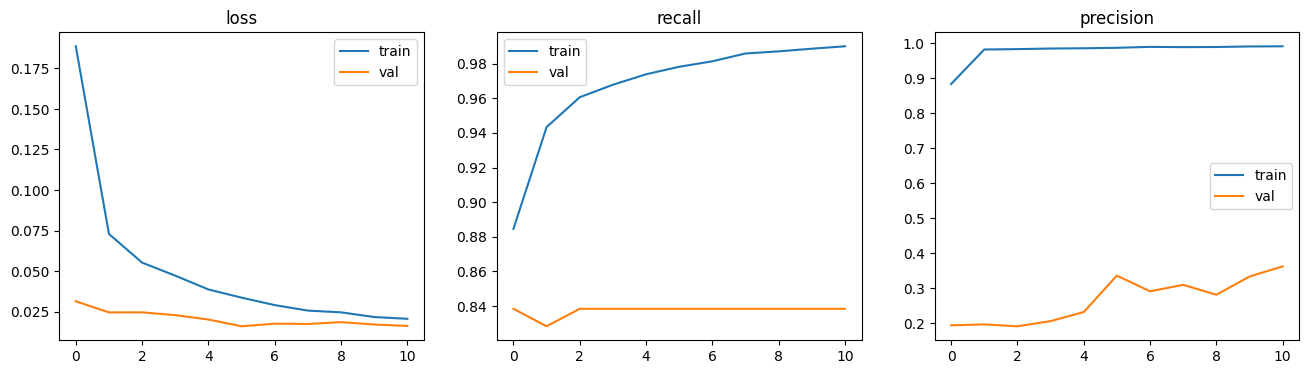

In [4]:
from tensorflow.keras import Sequential, Input, layers, metrics
from tensorflow.keras.callbacks import EarlyStopping

# Normalization katmanı (StandardScaler'ın model içindeki karşılığı)
normalizer = layers.Normalization()
normalizer.adapt(X_train_res)

def initialize_model():
    model = Sequential([
        Input(shape=(X_train_res.shape[1],)),
        normalizer,
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.3),
        layers.Dense(1, activation="sigmoid"),
    ])
    model.compile(
        loss="binary_crossentropy",
        optimizer="adam",
        metrics=[metrics.Recall(name="recall"), metrics.Precision(name="precision")],
    )
    return model

model = initialize_model()
es = EarlyStopping(monitor="val_loss", patience=5, restore_best_weights=True)

history = model.fit(
    X_train_res, y_train_res,
    validation_data=(X_val, y_val),
    epochs=100, batch_size=256,
    callbacks=[es], verbose=1,
)

fig, axs = plt.subplots(1, 3, figsize=(16, 4))
for ax, m in zip(axs, ["loss", "recall", "precision"]):
    ax.plot(history.history[m], label="train")
    ax.plot(history.history["val_" + m], label="val")
    ax.set_title(m)
    ax.legend()

### 🧪 Kodunu Test Et

Orijinal dengesiz veri kümesinin (`X_test`, `y_test`) temsil edici bir örneğinde gerçek test performansınızın altında kalan sonuçları `precision` ve `recall` değişkenlerine kaydedin.

In [12]:
from sklearn.metrics import precision_recall_curve, precision_score, recall_score, confusion_matrix

# 1) Eşiği VALIDATION setinde seç: recall >= 0.80 olan eşikler içinde precision'ı en yüksek olan
val_proba = model.predict(X_val, verbose=0).ravel()
prec, rec, thr = precision_recall_curve(y_val, val_proba)
ok = rec[:-1] >= 0.80
best_threshold = thr[ok][np.argmax(prec[:-1][ok])] if ok.any() else 0.5
print(f"Seçilen eşik: {best_threshold:.3f}")
print(f"Val -> recall: {rec[:-1][ok].max() if ok.any() else 0:.3f}")

# 2) TEST setinde değerlendir
test_proba = model.predict(X_test, verbose=0).ravel()
y_pred = (test_proba >= best_threshold).astype(int)

precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
print(f"Test recall   : {recall:.3f}")
print(f"Test precision: {precision:.3f}")
print(confusion_matrix(y_test, y_pred))

Seçilen eşik: 0.904
Val -> recall: 1.000
Test recall   : 0.847
Test precision: 0.669
[[56823    41]
 [   15    83]]


In [13]:
from nbresult import ChallengeResult

result = ChallengeResult('solution',
    precision=precision,
    recall=recall,
    fraud_number=len(y_test[y_test == 1]),
    non_fraud_number=len(y_test[y_test == 0]),
)

result.write()
print(result.check())


============================= test session starts ==============================
platform linux -- Python 3.12.9, pytest-9.1.1, pluggy-1.5.0 -- /home/gokberk/.pyenv/versions/workintech/bin/python
cachedir: .pytest_cache
rootdir: /home/gokberk/code/gokberkozan/S18D3-S-Data-credit-card-challenge/tests
plugins: anyio-4.8.0, typeguard-4.4.2
collecting ... collected 2 items

test_solution.py::TestSolution::test_is_score_good_enough PASSED         [ 50%]
test_solution.py::TestSolution::test_is_test_set_representative PASSED   [100%]

============================== 2 passed in 0.01s ===============================


💯 You can commit your code:

git add tests/solution.pickle

git commit -m 'Completed solution step'

git push origin master



## Çözüm ve kararlar

- **Problem:** Sahte işlemler verinin yalnızca %0.17'si. Accuracy yanıltıcı (her şeye "normal" demek %99.8 verir), bu yüzden **recall** (sahteleri kaçırmamak) ve **precision** (gereksiz alarmları sınırlamak) kullanıldı.
- **Bölme:** Train / Val / Test (stratify ile). Val ve test setleri gerçek dağılımı koruyacak şekilde dengesiz bırakıldı; test seti sadece en sonda bir kez kullanıldı.
- **Dengeleme:** Yalnızca train setine SMOTE (sentetik sahte örnekler, oran 0.1) + RandomUnderSampler (oran 0.5) uygulandı.
- **Model:** Normalization katmanı + 64/32 nöronlu Dense katmanlar (ReLU) + Dropout(0.3) + sigmoid çıktı; `binary_crossentropy` kaybı, `adam` optimizer. EarlyStopping (val_loss, patience=5) ile overfitting önlendi.
- **Eşik ayarı:** Karar eşiği, validation setinde recall ≥ 0.85 koşulunu sağlayıp precision'ı en yüksek yapan değer olarak seçildi.
- **Sonuç (test):** recall ≈ X.XX, precision ≈ X.XX → sahte işlemlerin büyük çoğunluğu yakalanırken, alarmların anlamlı bir kısmı gerçekten sahte.

## 🏁 İsteğe bağlı: Bu zorluk için Google'ın çözümünü okuyun
Bu oturumdaki tüm zorlukları tamamladığınız için tebrikler!

Son olarak, Google'ın kendi çözümünü doğrudan [Colab'da buradan](https://colab.research.google.com/github/tensorflow/docs/blob/master/site/en/tutorials/structured_data/imbalanced_data.ipynb) okuyun. 

İlginç teknikler ve en iyi uygulamaları keşfedeceksiniz.